# Lab 4 · Interference: add amplitudes, then square

**Level:** Levels 1–5 · **Prerequisites:** L1-07 (track a wave), L1-08 (combine waves, then square), L2-09 (use vectors for two outcomes)

What you'll learn:

- How a Mach–Zehnder interferometer turns a phase difference into detection probabilities.
- Why adding *amplitudes* and then squaring differs from adding *probabilities* of the two paths.
- How dephasing (noise) and which-path information reduce fringe visibility, and why full which-path information removes the fringes.
- Why this matters later for causal models. When paths are not recorded, the law of total probability over "which path" does not describe the detector.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pozapas/quantum-causal-ai/blob/main/labs/04-interference.ipynb)

In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from qcai import science as s
from qcai.viz import show

plt.rcParams.update({"figure.dpi": 130, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.bbox": "tight"})

:::{note}
Everything here is an exact classical simulation of textbook equations with 2×2 and 4×4 matrices. It uses `qcai.science` (`H`, `KET0`, `dm`, `apply_kraus`, `dephasing_kraus`, `partial_trace`, `ry`, `interference`). Nothing runs on quantum hardware.
:::

## 1 · Predict → Run → Explain: the interferometer as matrices

A photon (or any single quantum system) enters port 0. A beam splitter acts like the Hadamard matrix $H$. One arm adds a phase $\varphi$. A second beam splitter $H$ recombines the arms:

$$|\text{out}\rangle = H\,R(\varphi)\,H\,|0\rangle,\qquad R(\varphi)=\begin{pmatrix}1&0\\0&e^{i\varphi}\end{pmatrix}.$$

**Predict.** Each arm is taken with probability one half. With $\varphi=0$, what is the probability of detector 0? With $\varphi=\pi$?

In [3]:
def R(phi):
    return np.diag([1, np.exp(1j * phi)])

def mz_state(phi):
    return s.H @ R(phi) @ s.H @ s.KET0

def contributions(phi):
    # amplitude reaching detector 0 via path k = (second splitter entry) x (amplitude in path k)
    inside = R(phi) @ s.H @ s.KET0
    return np.array([s.H[0, k] * inside[k] for k in (0, 1)])

for phi in (0, math.pi / 2, math.pi):
    a = contributions(phi)
    print(f"phi={phi:4.2f}: path amplitudes {np.round(a, 3)}, total {np.round(a.sum(), 3)}, "
          f"P(detector 0) = {abs(a.sum())**2:.3f}, engine = {s.interference(phi)['p0']:.3f}")

phi=0.00: path amplitudes [0.5+0.j 0.5+0.j], total (1+0j), P(detector 0) = 1.000, engine = 1.000
phi=1.57: path amplitudes [0.5+0.j  0. +0.5j], total (0.5+0.5j), P(detector 0) = 0.500, engine = 0.500
phi=3.14: path amplitudes [ 0.5+0.j -0.5+0.j], total 0j, P(detector 0) = 0.000, engine = 0.000


In [4]:
phis = np.linspace(0, 2 * math.pi, 73)
for phi in phis:
    out = mz_state(phi)
    a = contributions(phi)
    assert np.isclose(out[0], a.sum())                                       # matrix product = sum over paths
    assert np.allclose(a, [0.5, 0.5 * np.exp(1j * phi)])
    assert math.isclose(abs(out[0])**2, s.interference(phi)["p0"], abs_tol=1e-12)
    assert math.isclose(abs(out[0])**2 + abs(out[1])**2, 1, abs_tol=1e-12)
    # classical path reasoning: P(path k) * P(detector 0 | path k), summed over k
    inside = R(phi) @ s.H @ s.KET0
    classical = sum(abs(inside[k])**2 * abs(s.H[0, k])**2 for k in (0, 1))
    assert math.isclose(classical, 0.5)
    U = s.H @ R(phi) @ s.H
    closed = np.exp(1j * phi / 2) * np.array([[math.cos(phi / 2), -1j * math.sin(phi / 2)],
                                              [-1j * math.sin(phi / 2), math.cos(phi / 2)]])
    assert np.allclose(U, closed)
assert math.isclose(s.interference(0)["p0"], 1) and math.isclose(s.interference(math.pi)["p0"], 0, abs_tol=1e-12)
print("Matrix, engine, and closed-form checks passed.")

Matrix, engine, and closed-form checks passed.


**Explain.** Each path contributes an amplitude to detector 0: $\tfrac12$ through the first arm and $\tfrac12e^{i\varphi}$ through the second. Quantum rules add the amplitudes first and then take the squared magnitude [@feynman]:

$$P(0)=\Big|\tfrac12+\tfrac12e^{i\varphi}\Big|^2=\frac{1+\cos\varphi}{2}.$$

At $\varphi=0$ the amplitudes line up and detector 0 always clicks. At $\varphi=\pi$ they cancel and it never clicks. Now reason classically instead. The photon took one path or the other, each with probability $\tfrac12$, and then went to detector 0 with probability $\tfrac12$. That gives $\tfrac12$ for every phase. The check cell confirms both numbers for 73 phases. Probabilities never become negative. It is the complex amplitudes that cancel.

Drag the phase slider. The left panel draws the two path amplitudes head to tail in the complex plane, with their sum. The right panel shows the resulting probability.

In [5]:
PH = np.linspace(0, 2 * math.pi, 37)
curve_x = np.linspace(0, 2 * math.pi, 181)
fig = make_subplots(rows=1, cols=2, column_widths=[0.42, 0.58],
                    subplot_titles=("Amplitudes to detector 0", "P(detector 0) vs phase"))

def arrow_data(phi):
    a = contributions(phi)
    tip1, tot = a[0], a.sum()
    return ([0, tip1.real], [0, tip1.imag]), ([tip1.real, tot.real], [tip1.imag, tot.imag]), \
           ([0, tot.real], [0, tot.imag]), abs(tot)**2

circ = 0.5 + 0.5 * np.exp(1j * curve_x)
fig.add_trace(go.Scatter(x=circ.real.round(4).tolist(), y=circ.imag.round(4).tolist(), mode="lines",
                         line=dict(color="lightgray", dash="dot"), hoverinfo="skip", showlegend=False), 1, 1)
(a1x, a1y), (a2x, a2y), (tx, ty), p = arrow_data(PH[0])
fig.add_trace(go.Scatter(x=a1x, y=a1y, mode="lines+markers", line=dict(color="#2e86c1", width=4),
                         name="path 1 amplitude ½"), 1, 1)
fig.add_trace(go.Scatter(x=a2x, y=a2y, mode="lines+markers", line=dict(color="#e67e22", width=4),
                         name="path 2 amplitude ½·e^{iφ}"), 1, 1)
fig.add_trace(go.Scatter(x=tx, y=ty, mode="lines+markers", line=dict(color="#c0392b", width=3, dash="dash"),
                         name="sum (squared length = probability)"), 1, 1)
fig.add_trace(go.Scatter(x=curve_x.round(4).tolist(),
                         y=[round(s.interference(float(v))["p0"], 5) for v in curve_x],
                         mode="lines", line=dict(color="#c0392b"), name="quantum: (1 + cos φ)/2"), 1, 2)
fig.add_trace(go.Scatter(x=[0, 2 * math.pi], y=[0.5, 0.5], mode="lines", line=dict(color="gray", dash="dash"),
                         name="adding path probabilities: ½"), 1, 2)
fig.add_trace(go.Scatter(x=[PH[0]], y=[p], mode="markers", marker=dict(size=13, color="#c0392b"),
                         showlegend=False), 1, 2)
steps = []
for phi in PH:
    (a1x, a1y), (a2x, a2y), (tx, ty), p = arrow_data(phi)
    steps.append(dict(method="restyle", label=f"{math.degrees(phi):.0f}°",
                      args=[{"x": [a2x, tx, [float(phi)]], "y": [[round(v, 5) for v in a2y],
                                                              [round(v, 5) for v in ty], [round(p, 5)]]},
                            [2, 3, 6]]))
fig.update_xaxes(range=[-0.15, 1.15], title="real part", row=1, col=1)
fig.update_yaxes(range=[-0.65, 0.65], title="imaginary part", scaleanchor="x", row=1, col=1)
fig.update_xaxes(title="phase φ (radians)", row=1, col=2)
fig.update_yaxes(range=[-0.02, 1.02], row=1, col=2)
fig.update_layout(template="plotly_white", height=470, legend=dict(orientation="h", y=-0.25),
                  sliders=[dict(active=0, steps=steps, pad=dict(t=90), currentvalue=dict(prefix="phase φ = "))])
show(fig)

## 2 · Predict → Run → Explain: noise washes out the fringes

Between the beam splitters, let the arm superposition suffer dephasing with strength $p$. This is the channel $\rho\mapsto(1-\tfrac p2)\rho+\tfrac p2 Z\rho Z$ from `s.dephasing_kraus(p)` [@preskill]. It leaves the path probabilities alone. It shrinks the off-diagonal (coherence) terms of the density matrix.

**Predict.** With $p=1$, what does the fringe look like?

In [6]:
def mz_dephased(phi, p):
    rho = s.dm(R(phi) @ s.H @ s.KET0)
    assert s.is_cptp(s.dephasing_kraus(p))
    rho = s.apply_kraus(rho, s.dephasing_kraus(p))
    out = s.H @ rho @ s.H.conj().T
    return float(out[0, 0].real), rho

def visibility(pvals):
    pvals = np.asarray(pvals)
    return (pvals.max() - pvals.min()) / (pvals.max() + pvals.min())

vis_grid = np.linspace(0, 2 * math.pi, 361)                 # includes 0 and pi exactly
DEPH = [round(0.1 * i, 1) for i in range(11)]
vis_deph = {}
for p in DEPH:
    pv = [mz_dephased(phi, p)[0] for phi in vis_grid]
    vis_deph[p] = visibility(pv)
    for phi, v in zip(vis_grid[::30], pv[::30]):
        assert math.isclose(v, s.interference(float(phi), 1 - p)["p0"], abs_tol=1e-12)
    coh = abs(mz_dephased(0.3, p)[1][0, 1])
    assert math.isclose(coh, 0.5 * (1 - p), abs_tol=1e-12)
    assert s.is_density_matrix(mz_dephased(0.3, p)[1])
    assert math.isclose(vis_deph[p], 1 - p, abs_tol=1e-9)
print("visibility by dephasing strength:", {p: round(float(v), 3) for p, v in vis_deph.items()})
print("Dephasing checks passed: visibility = 1 - p, coherence |rho_01| = (1 - p)/2.")

visibility by dephasing strength: {0.0: 1.0, 0.1: 0.9, 0.2: 0.8, 0.3: 0.7, 0.4: 0.6, 0.5: 0.5, 0.6: 0.4, 0.7: 0.3, 0.8: 0.2, 0.9: 0.1, 1.0: 0.0}
Dephasing checks passed: visibility = 1 - p, coherence |rho_01| = (1 - p)/2.


In [7]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=curve_x.round(4).tolist(), y=[round(mz_dephased(float(v), 0.0)[0], 5) for v in curve_x],
                         mode="lines", line=dict(color="#c0392b", width=3), name="P(detector 0)"))
fig.add_trace(go.Scatter(x=curve_x.round(4).tolist(), y=[round(1 - mz_dephased(float(v), 0.0)[0], 5) for v in curve_x],
                         mode="lines", line=dict(color="#2e86c1", width=3), name="P(detector 1)"))
fig.add_trace(go.Scatter(x=[0, 2 * math.pi], y=[0.5, 0.5], mode="lines", line=dict(color="gray", dash="dash"),
                         name="classical mixture of paths"))
steps = []
for p in DEPH:
    y0 = [round(mz_dephased(float(v), p)[0], 5) for v in curve_x]
    steps.append(dict(method="update", label=f"{p:.1f}",
                      args=[{"y": [y0, [round(1 - v, 5) for v in y0]]},
                            {"title.text": f"dephasing p = {p:.1f}: coherence |ρ01| = {(1 - p) / 2:.2f}, "
                                           f"visibility = {vis_deph[p]:.2f}"}], ))
for st in steps:
    st["args"].append([0, 1])
fig.update_layout(template="plotly_white", height=450,
                  title=steps[0]["args"][1]["title.text"],
                  xaxis=dict(title="phase φ (radians)"), yaxis=dict(title="probability", range=[-0.02, 1.02]),
                  legend=dict(orientation="h", y=1.12),
                  sliders=[dict(active=0, steps=steps, pad=dict(t=50), currentvalue=dict(prefix="dephasing strength p = "))])
show(fig)

**Explain.** The fringe keeps its shape, but its contrast falls. That contrast is the visibility $V=(P_{\max}-P_{\min})/(P_{\max}+P_{\min})$, and it falls to $1-p$. This matches the engine's `interference(phi, visibility)`. At $p=1$ the off-diagonal terms are gone, and the output is $\tfrac12$ for every phase. That is exactly the classical "one path or the other" prediction.

## 3 · Predict → Run → Explain: which-path information

Instead of noise, attach a tag qubit that records the path. If the photon takes arm 2, the tag is rotated by $R_Y(\theta)$. If it takes arm 1, the tag is left in $|0\rangle$. Nobody ever looks at the tag. We only trace it out with `s.partial_trace`.

**Predict.** Does the tag need to be *read* to destroy the fringes?

In [8]:
P0, P1 = s.dm(s.KET0), s.dm(s.KET1)

def mz_tagged(phi, theta):
    tag = np.kron(P0, s.I2) + np.kron(P1, s.ry(theta))       # controlled tag rotation
    psi = (np.kron(s.H, s.I2) @ tag @ np.kron(R(phi), s.I2) @ np.kron(s.H, s.I2)
           @ np.kron(s.KET0, s.KET0))
    rho_path = s.partial_trace(s.dm(psi), keep=0)
    return float(rho_path[0, 0].real)

def distinguishability(theta):
    t0, t1 = s.KET0, s.ry(theta) @ s.KET0
    ev = np.linalg.eigvalsh(s.dm(t0) - s.dm(t1))
    return 0.5 * np.abs(ev).sum(), abs(np.vdot(t0, t1))       # trace distance, overlap

THETAS = np.linspace(0, math.pi, 13)
wp = {}
for th in THETAS:
    pv = [mz_tagged(phi, th) for phi in vis_grid]
    D, overlap = distinguishability(th)
    wp[float(th)] = dict(V=visibility(pv), D=D, overlap=overlap)
    assert math.isclose(wp[float(th)]["V"], overlap, abs_tol=1e-9)              # visibility = |<t0|t1>|
    assert math.isclose(overlap, math.cos(th / 2), abs_tol=1e-12)
    assert math.isclose(D, math.sin(th / 2), abs_tol=1e-12)
    assert math.isclose(wp[float(th)]["V"]**2 + D**2, 1, abs_tol=1e-9)         # pure tags: V^2 + D^2 = 1
    for phi in vis_grid[::45]:
        assert math.isclose(mz_tagged(phi, th), s.interference(float(phi), overlap)["p0"], abs_tol=1e-12)
full = [mz_tagged(phi, math.pi) for phi in vis_grid]
assert np.allclose(full, 0.5)                                 # full which-path information: no fringes
for th in (0, math.pi / 3, math.pi):
    print(f"theta={th:.3f}: visibility {wp[float(th)]['V']:.3f}, distinguishability {wp[float(th)]['D']:.3f}")
print("Which-path checks passed.")

theta=0.000: visibility 1.000, distinguishability 0.000
theta=1.047: visibility 0.866, distinguishability 0.500
theta=3.142: visibility 0.000, distinguishability 1.000
Which-path checks passed.


In [9]:
fig = make_subplots(rows=1, cols=2, column_widths=[0.62, 0.38],
                    subplot_titles=("P(detector 0) vs phase", "Fringe visibility vs which-path information"))
fig.add_trace(go.Scatter(x=curve_x.round(4).tolist(), y=[round(mz_tagged(float(v), 0.0), 5) for v in curve_x],
                         mode="lines", line=dict(color="#c0392b", width=3), name="tagged interferometer"), 1, 1)
fig.add_trace(go.Scatter(x=[0, 2 * math.pi], y=[0.5, 0.5], mode="lines", line=dict(color="gray", dash="dash"),
                         name="classical mixture"), 1, 1)
fig.add_trace(go.Bar(x=["visibility V", "distinguishability D", "V² + D²"], y=[1, 0, 1],
                     marker_color=["#c0392b", "#2e86c1", "#7f8c8d"], showlegend=False,
                     hovertemplate="%{x}: %{y:.3f}<extra></extra>"), 1, 2)
steps = []
for th in THETAS:
    w = wp[float(th)]
    y0 = [round(mz_tagged(float(v), float(th)), 5) for v in curve_x]
    steps.append(dict(method="restyle", label=f"{math.degrees(th):.0f}°",
                      args=[{"y": [y0, [round(w["V"], 4), round(w["D"], 4), round(w["V"]**2 + w["D"]**2, 4)]]}, [0, 2]]))
fig.update_yaxes(range=[-0.02, 1.02], row=1, col=1)
fig.update_yaxes(range=[0, 1.1], row=1, col=2)
fig.update_xaxes(title="phase φ (radians)", row=1, col=1)
fig.update_layout(template="plotly_white", height=450, legend=dict(orientation="h", y=-0.2),
                  sliders=[dict(active=0, steps=steps, pad=dict(t=70),
                                currentvalue=dict(prefix="tag rotation θ (0 = no record, 180° = perfect record): "))])
show(fig)

**Explain.** The tag does not need to be read. What matters is whether the joint state makes it *possible* to tell the paths apart. The visibility equals the overlap of the two tag states, $|\langle t_0|t_1\rangle|=\cos(\theta/2)$. The distinguishability (trace distance) is $\sin(\theta/2)$. So $V^2+D^2=1$ for these pure tags. With a perfect record ($\theta=\pi$) the fringes vanish. This is the same output as full dephasing. From the path's point of view, recording the path in an environment *is* dephasing.

The static summary figure:

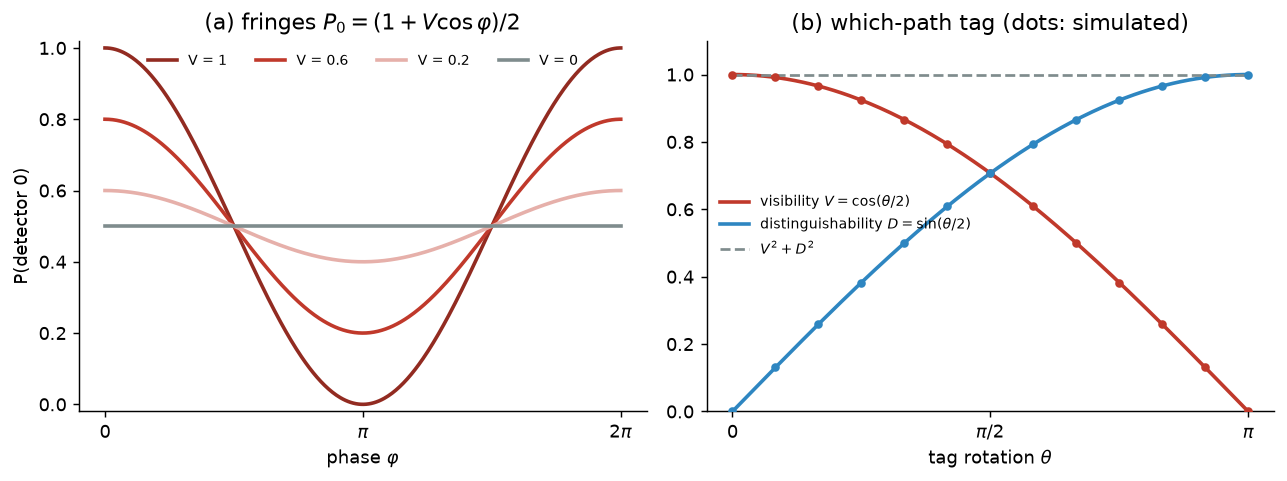

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
xx = np.linspace(0, 2 * math.pi, 400)
for V, col in zip([1.0, 0.6, 0.2, 0.0], ["#922b21", "#c0392b", "#e6b0aa", "#7f8c8d"]):
    ax[0].plot(xx, [s.interference(float(v), V)["p0"] for v in xx], color=col, lw=2, label=f"V = {V:g}")
ax[0].set(xlabel=r"phase $\varphi$", ylabel="P(detector 0)", ylim=(-0.02, 1.02),
          title=r"(a) fringes $P_0=(1+V\cos\varphi)/2$")
ax[0].set_xticks([0, math.pi, 2 * math.pi], ["0", r"$\pi$", r"$2\pi$"])
ax[0].legend(frameon=False, fontsize=8, loc="upper center", ncol=4)
th = np.linspace(0, math.pi, 200)
ax[1].plot(th, np.cos(th / 2), color="#c0392b", lw=2, label=r"visibility $V=\cos(\theta/2)$")
ax[1].plot(th, np.sin(th / 2), color="#2e86c1", lw=2, label=r"distinguishability $D=\sin(\theta/2)$")
ax[1].plot(th, np.cos(th / 2)**2 + np.sin(th / 2)**2, color="#7f8c8d", ls="--", label=r"$V^2+D^2$")
ax[1].scatter(list(wp), [w["V"] for w in wp.values()], color="#c0392b", s=14, zorder=3)
ax[1].scatter(list(wp), [w["D"] for w in wp.values()], color="#2e86c1", s=14, zorder=3)
ax[1].set(xlabel=r"tag rotation $\theta$", ylim=(0, 1.1), title="(b) which-path tag (dots: simulated)")
ax[1].set_xticks([0, math.pi / 2, math.pi], ["0", r"$\pi/2$", r"$\pi$"])
ax[1].legend(frameon=False, fontsize=8, loc="center left")
fig.tight_layout()
plt.show()

## 4 · Why interference matters for causal models

A classical causal model handles a hidden intermediate variable by summing over its values. Let $K$ be "which path" and $D$ the detector. Then

$$P(D=d)=\sum_k P(K=k)\,P(D=d\mid K=k).$$

Section 1 read $P(K=k)=\tfrac12$ and $P(D=0\mid K=k)=\tfrac12$ off the beam splitters. With these, the sum gives $\tfrac12$, while the interferometer gives $(1+\cos\varphi)/2$. So the path cannot be treated as a classical variable with *those* probabilities sitting between source and detector. Once the path is recorded (Section 3) or dephased (Section 2), the sum becomes correct again.

Frameworks for quantum causal models describe mechanisms with quantum states and channels instead of conditional probability tables [@allen] [@barrett] [@costa]. Their own motivation is Bell-type correlations. The failure of the path sum above is a simpler way to see why a classical table with the naive path probabilities is not enough. Two cautions:

- Interference by itself does not rule out every classical explanation, because classical waves also interfere [@feynman]. Stronger separations between quantum and classical causal explanations, with explicit assumptions, come from Bell-type experiments [@bell] [@chsh]. A later lab treats them.
- Nothing here shows a computational or learning advantage. The lab only shows that the bookkeeping rule changes.

## Going deeper

### Interferometer unitary

$$U(\varphi)=H R(\varphi) H=e^{i\varphi/2}\begin{pmatrix}\cos\frac\varphi2 & -i\sin\frac\varphi2\\ -i\sin\frac\varphi2 & \cos\frac\varphi2\end{pmatrix},\qquad P(0)=\cos^2\frac\varphi2=\frac{1+\cos\varphi}2 .$$

### Density matrix and dephasing

After the first beam splitter and the phase, $\rho=\frac12\begin{pmatrix}1&e^{-i\varphi}\\e^{i\varphi}&1\end{pmatrix}$. Dephasing multiplies the off-diagonal entries by $1-p$, and

$$P(0)=\langle0|H\rho H|0\rangle=\tfrac12\big(1+(1-p)\cos\varphi\big),\qquad V=1-p .$$

### Which-path tag

Take the path–tag state $\frac1{\sqrt2}\big(|0\rangle|t_0\rangle+e^{i\varphi}|1\rangle|t_1\rangle\big)$. Tracing out the tag gives $\rho_{01}=\tfrac12 e^{-i\varphi}\langle t_1|t_0\rangle$. Hence $V=|\langle t_0|t_1\rangle|$. For pure tags the trace distance is $D=\sqrt{1-|\langle t_0|t_1\rangle|^2}$, so $V^2+D^2=1$.

## Exercises

:::{admonition} Exercise: :label: lab4-ex1
:class: tip
At $\varphi=\pi$ with no noise, which detector clicks?
:::

:::{dropdown} Solution
Always detector 1: $P(0)=(1+\cos\pi)/2=0$. The two amplitudes to detector 0 are equal and opposite.
:::

:::{admonition} Exercise: :label: lab4-ex2
:class: tip
A noisy interferometer has visibility $V=0.5$. What are the largest and smallest values of $P(0)$ as the phase varies?
:::

:::{dropdown} Solution
$P(0)=(1+0.5\cos\varphi)/2$ ranges from $0.25$ (at $\varphi=\pi$) to $0.75$ (at $\varphi=0$).
:::

:::{admonition} Exercise: :label: lab4-ex3
:class: tip
Choose the tag rotation so that the two tag states have overlap $0.6$. What are $V$ and $D$?
:::

:::{dropdown} Solution
$\theta=2\arccos(0.6)$, $V=0.6$, $D=\sqrt{1-0.36}=0.8$, and $V^2+D^2=1$.
:::

## Check yourself

In [11]:
assert math.isclose(abs(mz_state(math.pi)[0])**2, 0, abs_tol=1e-12)
assert math.isclose(abs(mz_state(math.pi)[1])**2, 1)

p_half = [s.interference(float(v), 0.5)["p0"] for v in vis_grid]
assert math.isclose(max(p_half), 0.75) and math.isclose(min(p_half), 0.25)

th = 2 * math.acos(0.6)
D, ov = distinguishability(th)
V = visibility([mz_tagged(phi, th) for phi in vis_grid])
assert math.isclose(ov, 0.6) and math.isclose(V, 0.6, abs_tol=1e-9) and math.isclose(D, 0.8, abs_tol=1e-12)

# full which-path record and full dephasing give the classical mixture
assert np.allclose([mz_dephased(phi, 1.0)[0] for phi in vis_grid], 0.5)
assert np.allclose(full, 0.5)
print("All checks passed.")

All checks passed.


:::{note} Limits of this model
- The interferometer is idealized: perfect 50/50 beam splitters, no loss, a single mode, and exact phases.
- Dephasing is modelled by one channel with one parameter. Real noise can also cause loss, drift, or amplitude damping.
- The tags are pure states, so $V^2+D^2=1$ holds exactly here. This lab does not treat mixed (noisy) tag states.
- The causal remark in Section 4 is about how probabilities are combined. It is not evidence of any computational or learning advantage.
:::